In [1]:
import pandas as pd
import matplotlib.pyplot as plt
from gsec_data import build_table
from gsec_changes import all_changes

table = build_table("data")
daily, weekly, monthly = all_changes(table)

print(table.shape)
print("rows with a daily change:", daily.notna().all(axis=1).sum())
print("rows with a weekly change:", weekly.notna().all(axis=1).sum())
print("rows with a monthly change:", monthly.notna().all(axis=1).sum())

(32, 9)
rows with a daily change: 10
rows with a weekly change: 17
rows with a monthly change: 27


In [2]:
print(daily.loc["2026-10-13", [1, 10]].round(1))
print("weekly 10Y, 16 Oct:", weekly.loc["2026-10-16", 10].round(1))
print("monthly 10Y, 16 Oct:", monthly.loc["2026-10-16", 10].round(1))

1     21.1
10    -3.3
Name: 2026-10-13 00:00:00, dtype: float64
weekly 10Y, 16 Oct: 2.7
monthly 10Y, 16 Oct: 31.4


In [3]:
table.loc[["2026-10-12", "2026-10-13"], [1, 10]]
table.loc[["2026-10-09", "2026-10-16"], [10]]
table.loc[["2026-09-18", "2026-10-16"], [10]]

,10
date,
2026-09-18,7.088492
2026-10-16,7.402676


In [4]:
latest = table.index[-1]
summary = pd.DataFrame({
    "daily": daily.loc[latest],
    "weekly": weekly.loc[latest],
    "monthly": monthly.loc[latest],
}).round(1)
summary.index.name = "tenor (years)"
print("Changes to", latest.date())
summary

Changes to 2026-10-16


,daily,weekly,monthly
tenor (years),,,
1,4.3,28.4,42.0
2,0.3,8.1,28.8
3,1.9,18.4,44.8
5,-2.9,18.1,37.0
7,-3.7,8.3,35.7
10,-1.6,2.7,31.4
15,-0.7,4.6,28.4
20,-6.9,-3.8,8.6
30,-1.3,5.9,17.5


In [5]:
s = daily.stack()
print(s.reindex(s.abs().sort_values(ascending=False).head(8).index).round(1))

date        tenor (years)
2026-10-13  1                21.1
2026-10-14  2                14.0
2026-10-12  3                13.2
            5                12.9
2026-08-31  3                11.2
2026-10-12  20                9.7
2026-10-13  20               -9.3
2026-10-08  2                -8.9
dtype: float64


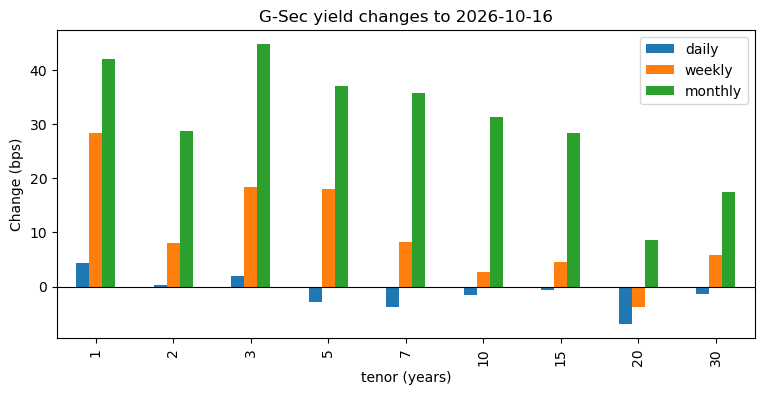

In [6]:
summary.plot(kind="bar", figsize=(9, 4))
plt.ylabel("Change (bps)")
plt.title(f"G-Sec yield changes to {latest.date()}")
plt.axhline(0, color="black", linewidth=0.8)
plt.show()

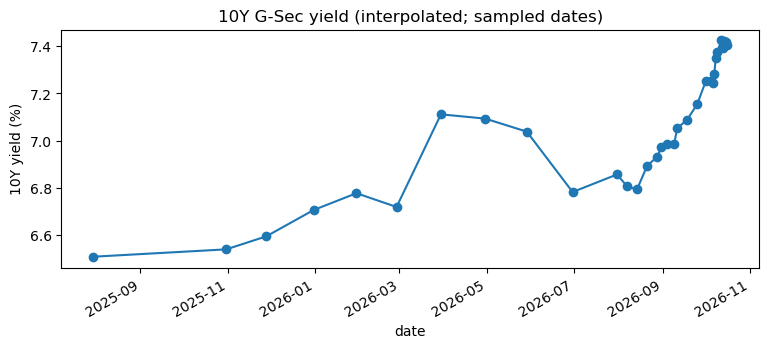

In [7]:
table[10].plot(marker="o", figsize=(9, 3.5))
plt.ylabel("10Y yield (%)")
plt.title("10Y G-Sec yield (interpolated; sampled dates)")
plt.show()

In [8]:
daily.to_csv("data/changes_daily_bps.csv")
weekly.to_csv("data/changes_weekly_bps.csv")
monthly.to_csv("data/changes_monthly_bps.csv")